# Bengali Long-form Speaker Diarization — Starter Notebook

**Audio → ML-based Voice Activity Detection (Silero) → windows → ECAPA embeddings → clustering → speaker turns → CSV output**




## 1) Dependencies install

In [1]:

!pip -q install soundfile torchaudio speechbrain scikit-learn tqdm silero-vad

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 864.1/864.1 kB 15.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 91.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 95.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.6/121.6 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 8.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 788.2/788.2 kB 54.4 MB/s eta 0:00:00


## 2) Import setup

In [2]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio
from tqdm.auto import tqdm

from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import normalize

import matplotlib.pyplot as plt

## 3) Paths + Device configuration

In [3]:
# === FILE PATH ===
AUDIO_DIR = Path("/kaggle/input/dl-sprint-4-0-bengali-speaker-diarization-challenge/diarization/diarization/test/audio")          
OUT_PATH = Path("submission.csv")  

# === Device ===
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DEVICE

'cuda'

## 4) Collect files (and stems)

In [4]:
wav_paths = sorted(AUDIO_DIR.glob("*.wav"))
stems = [p.stem for p in wav_paths]

len(wav_paths), (wav_paths[0] if wav_paths else None)

(14,
 PosixPath('/kaggle/input/dl-sprint-4-0-bengali-speaker-diarization-challenge/diarization/diarization/test/audio/test_010.wav'))

## 5) Audio loader (mono float32 @ 16 kHz)
Reads an audio file, converts it to **mono** `float32`, and **resamples** to **16 kHz** (if needed) for consistent downstream VAD and embedding extraction.


In [5]:
def load_audio_mono_16k(path: str | Path, target_sr: int = 16000) -> np.ndarray:
    """Load audio file as mono float32 at target_sr."""
    wav, sr = sf.read(str(path))
    if wav.ndim == 2:
        wav = wav.mean(axis=1)
    wav = wav.astype(np.float32)

    if sr != target_sr:
        x = torch.from_numpy(wav).unsqueeze(0)
        resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=target_sr)
        wav = resampler(x).squeeze(0).cpu().numpy().astype(np.float32)
    return wav

## 6) Load ML-based Voice Activity Detection(VAD) model (Silero)
Loads the **Silero neural VAD** using the official `silero-vad` package (with an optional `torch.hub` fallback), supports **Torch/ONNX** variants, and places the VAD model on **CPU** for stable inference across environments.


In [6]:

USE_PIP = True   # set False to use torch.hub instead
USE_ONNX = False # set True to use ONNX model
VAD_DEVICE="cpu" # silero VAD is light-weight,okay with cpu 

if USE_PIP:
    from silero_vad import (
        load_silero_vad,
        get_speech_timestamps,
        read_audio,
        save_audio,
        VADIterator,
        collect_chunks,
    )
    silero_model = load_silero_vad(onnx=USE_ONNX)
else:
    silero_model, utils = torch.hub.load(
        repo_or_dir="snakers4/silero-vad",
        model="silero_vad",
        trust_repo=True,
        onnx=USE_ONNX,
    )
    (get_speech_timestamps, save_audio, read_audio, VADIterator, collect_chunks) = utils

silero_model.to(VAD_DEVICE)
silero_model.eval()


RecursiveScriptModule(
  original_name=VADRNNJITMerge
  (_model): RecursiveScriptModule(
    original_name=VADRNNJIT
    (stft): RecursiveScriptModule(
      original_name=STFT
      (padding): RecursiveScriptModule(original_name=ReflectionPad1d)
    )
    (encoder): RecursiveScriptModule(
      original_name=Sequential
      (0): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
        (activation): RecursiveScriptModule(original_name=ReLU)
        (reparam_conv): RecursiveScriptModule(original_name=Conv1d)
      )
      (1): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
        (activation): RecursiveScriptModule(original_name=ReLU)
        (reparam_conv): RecursiveScriptModule(original_name=Conv1d)
      )
      (2): RecursiveScriptModule(
        original_name=SileroVadBlock
        (se): RecursiveScriptModule(original_name=Identity)
     

## 7) Neural VAD → speech segments (Silero)
Runs **Silero VAD** on the full **16 kHz mono waveform** to extract speech regions as `(start_sec, end_sec)`. The main knobs are `vad_threshold` (strictness), `padding_ms` (context around speech), and `min_speech_ms` / `min_silence_ms` (smoothing), with a final merge step to handle overlaps.


In [7]:
def silero_vad_speech_segments(
    wav16k: np.ndarray,
    sr: int = 16000,
    vad_threshold: float = 0.5,
    padding_ms: int = 300,
    min_silence_ms: int = 200,
    min_speech_ms: int = 300,
):
    """
    Returns list of (start_sec, end_sec) speech segments using Silero neural VAD.
    Runs VAD on the full waveform (more robust than streaming chunk iteration).
    """
    assert sr == 16000, "Silero VAD expects 16kHz audio"

    x = torch.from_numpy(wav16k).float().to(VAD_DEVICE)  # Silero utils typically expect CPU tensor

    ts = get_speech_timestamps(
        x,
        silero_model,
        sampling_rate=sr,
        threshold=vad_threshold,
        min_speech_duration_ms=min_speech_ms,
        min_silence_duration_ms=min_silence_ms,
        speech_pad_ms=padding_ms,
    )


    segs = [(t["start"] / sr, t["end"] / sr) for t in ts]

    # Defensive merge in case of overlaps
    merged = []
    for s, e in sorted(segs):
        if not merged or s > merged[-1][1]:
            merged.append([s, e])
        else:
            merged[-1][1] = max(merged[-1][1], e)

    return [(float(s), float(e)) for s, e in merged]


### 7.1) Visual check: waveform + VAD speech segments
Overlay detected speech regions on the waveform to quickly spot missed speech or false alarms.


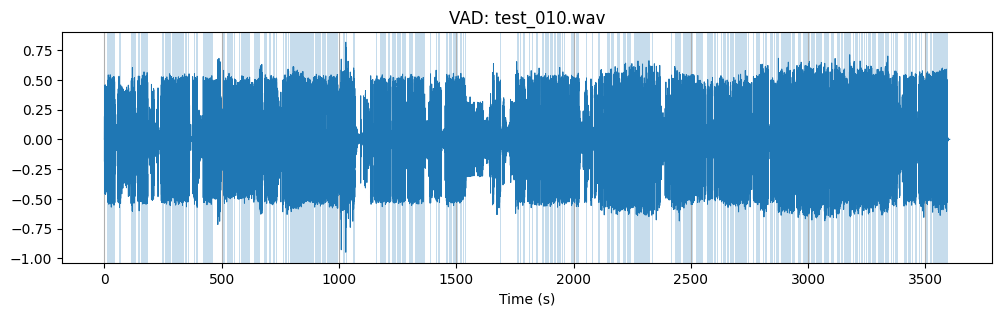

In [8]:
def plot_waveform_with_segments(wav, sr, segments, title="Waveform + VAD"):
    t = np.arange(len(wav)) / sr
    plt.figure(figsize=(12, 3))
    plt.plot(t, wav, linewidth=0.7)
    for s, e in segments:
        plt.axvspan(s, e, alpha=0.25)
    plt.xlabel("Time (s)")
    plt.title(title)
    plt.grid(True, axis="x")
    plt.show()

# Example on one file
if wav_paths:
    wav = load_audio_mono_16k(wav_paths[0], 16000)
    speech_segs = silero_vad_speech_segments(wav, sr=16000)
    plot_waveform_with_segments(wav, 16000, speech_segs, title=f"VAD: {wav_paths[0].name}")


## 8) Sliding windows inside speech segments
Creates overlapping windows `(ws, we)` to extract speaker embeddings.


In [9]:
def make_windows(segments, win_sec=1.5, hop_sec=0.75):
    """Create sliding windows (ws,we) inside each speech segment."""
    windows = []
    for s, e in segments:
        dur = e - s
        if dur <= win_sec:
            windows.append((s, e))
            continue
        t = s
        while t + win_sec <= e + 1e-6:
            windows.append((t, t + win_sec))
            t += hop_sec
        if windows and windows[-1][1] < e:
            windows.append((max(s, e - win_sec), e))

    # de-dup (rounding is only for identity keys)
    out, seen = [], set()
    for ws, we in windows:
        key = (round(ws, 3), round(we, 3))
        if key not in seen:
            out.append((float(ws), float(we)))
            seen.add(key)
    return out

## 9) Load speaker embedding model (SpeechBrain ECAPA-TDNN)
Loads a pretrained **ECAPA-TDNN speaker recognition model** (`spkrec-ecapa-voxceleb`) to convert speech audio into fixed-dimensional speaker embeddings for clustering.


In [10]:
from speechbrain.pretrained import EncoderClassifier

spk_model = EncoderClassifier.from_hparams(
    source="speechbrain/spkrec-ecapa-voxceleb",
    run_opts={"device": DEVICE},
)
"ECAPA model loaded" 

/usr/local/lib/python3.12/dist-packages/speechbrain/utils/torch_audio_backend.py:57: UserWarning: torchaudio._backend.list_audio_backends has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be removed from the 2.9 release. 
  available_backends = torchaudio.list_audio_backends()
/tmp/ipykernel_23/992280767.py:1: UserWarning: Module 'speechbrain.pretrained' was deprecated, redirecting to 'speechbrain.inference'. Please update your script. This is a change from SpeechBrain 1.0. See: https://github.com/speechbrain/speechbrain/releases/tag/v1.0.0
  from speechbrain.pretrained import EncoderClassifier


hyperparams.yaml: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.12/dist-packages/speechbrain/utils/torch_audio_backend.py:57: UserWarning: torchaudio._backend.list_audio_backends has been deprecated. This deprecation is part of a large refactoring effort to transition TorchAudio into a maintenance phase. The decoding and encoding capabilities of PyTorch for both audio and video are being consolidated into TorchCodec. Please see https://github.com/pytorch/audio/issues/3902 for more information. It will be removed from the 2.9 release. 
  available_backends = torchaudio.list_audio_backends()
/usr/local/lib/python3.12/dist-packages/speechbrain/utils/autocast.py:188: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  wrapped_fwd = torch.cuda.amp.custom_fwd(fwd, cast_inputs=cast_inputs)


embedding_model.ckpt:   0%|          | 0.00/83.3M [00:00<?, ?B/s]

mean_var_norm_emb.ckpt:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

classifier.ckpt:   0%|          | 0.00/5.53M [00:00<?, ?B/s]

label_encoder.txt: 0.00B [00:00, ?B/s]

'ECAPA model loaded'

## 10) Speaker embedding extraction (ECAPA-TDNN)
Computes a **fixed-dimensional speaker embedding** from a **mono 16 kHz** waveform using the pretrained ECAPA model in `torch.inference_mode()` (no gradients) and returns a `(D,)` `float32` NumPy vector for clustering.


In [11]:
@torch.inference_mode()
def ecapa_embedding(wav16k: np.ndarray) -> np.ndarray:
    """
    wav16k: mono float32, 16kHz
    returns: (D,) numpy embedding
    """
    x = torch.from_numpy(wav16k).unsqueeze(0).to(DEVICE)
    emb = spk_model.encode_batch(x)
    return emb.squeeze().detach().cpu().numpy().astype(np.float32)

## 11) Estimate number of speakers (silhouette on cosine distance)
Tries `k = 2..max_k` using agglomerative clustering on **L2-normalized embeddings** and selects the `k` with the best **silhouette score** (cosine metric) as a rough speaker-count estimate.


In [12]:
def estimate_num_speakers(embs: np.ndarray, max_k: int = 6) -> int:
    """Rough speaker count estimation using silhouette score on cosine distance."""
    n = len(embs)
    if n < 3:
        return 1
    max_k = min(max_k, n)
    if max_k <= 1:
        return 1

    X = normalize(embs)

    best_k = 1
    best_score = -1.0
    for k in range(2, max_k + 1):
        try:
            labels = AgglomerativeClustering(
                n_clusters=k, metric="cosine", linkage="average"
            ).fit_predict(X)
            if len(set(labels)) < 2:
                continue
            score = silhouette_score(X, labels, metric="cosine")
            if score > best_score:
                best_score = score
                best_k = k
        except Exception:
            continue

    return best_k

## 12) Cluster embeddings into speaker labels
Clusters the (normalized) window-level speaker embeddings into `n_speakers` groups using **agglomerative clustering** with **cosine distance** and **average linkage**, returning an integer label per window.


In [13]:
def cluster_embeddings(embs: np.ndarray, n_speakers: int) -> np.ndarray:
    if len(embs) == 0:
        return np.array([], dtype=int)
    if n_speakers <= 1 or len(embs) < 2:
        return np.zeros(len(embs), dtype=int)
    X = normalize(embs)
    labels = AgglomerativeClustering(
        n_clusters=n_speakers, metric="cosine", linkage="average"
    ).fit_predict(X)
    return labels.astype(int)

### 12.1) Visual check: embedding clusters (PCA to 2D)
Projects speaker embeddings to 2D to see whether predicted speakers form separable clusters.


In [14]:
from sklearn.decomposition import PCA

def plot_embedding_pca(embs, labels, title="Embedding PCA"):
    if len(embs) < 2:
        print("Not enough embeddings to plot.")
        return
    X = normalize(embs)
    Z = PCA(n_components=2).fit_transform(X)

    plt.figure(figsize=(6, 5))
    plt.scatter(Z[:, 0], Z[:, 1], c=labels, s=18)
    plt.title(title)
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.grid(True)
    plt.show()



In [15]:
# --- One-file debug run: compute embs + labels for visualization ---
test_path = wav_paths[0]

wav = load_audio_mono_16k(test_path, 16000)
speech_segs = silero_vad_speech_segments(wav, sr=16000)
windows = make_windows(speech_segs, win_sec=1.5, hop_sec=0.75)

embs = []
valid_windows = []
for ws, we in windows:
    s = int(ws * 16000)
    e = int(we * 16000)
    chunk = wav[s:e]
    if len(chunk) < int(0.4 * 16000):
        continue
    embs.append(ecapa_embedding(chunk))
    valid_windows.append((ws, we))

embs = np.vstack(embs) if len(embs) else np.empty((0, 192), dtype=np.float32)  # 192 is common for ECAPA

n_spk = estimate_num_speakers(embs, max_k=6) if len(embs) else 1
labels = cluster_embeddings(embs, n_speakers=n_spk) if len(embs) else np.array([], dtype=int)

len(embs), len(labels), n_spk


(2201, 2201, 5)

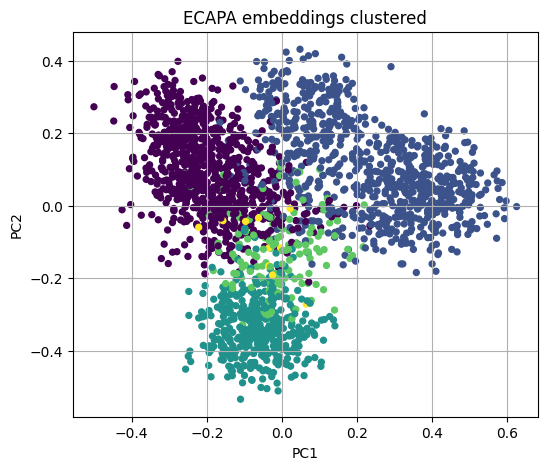

In [16]:
plot_embedding_pca(embs, labels, title="ECAPA embeddings clustered")


## 13) Convert labeled windows into speaker turns
Merges adjacent/overlapping windows that share the same speaker label into continuous **speaker turns** `(start_sec, end_sec, speaker_label)`, filtering very short turns and optionally bridging small same-speaker gaps.


In [17]:
def windows_to_turns(windows, labels, min_turn_sec=0.2):
    """Merge adjacent/overlapping same-speaker windows into turns."""
    if not windows:
        return []

    items = sorted(zip(windows, labels), key=lambda x: x[0][0])
    cur_s, cur_e = items[0][0]
    cur_lab = int(items[0][1])

    turns = []
    for (ws, we), lab in items[1:]:
        lab = int(lab)
        if lab == cur_lab and ws <= cur_e + 1e-3:
            cur_e = max(cur_e, we)
        else:
            if cur_e - cur_s >= min_turn_sec:
                turns.append((cur_s, cur_e, cur_lab))
            cur_s, cur_e, cur_lab = ws, we, lab

    if cur_e - cur_s >= min_turn_sec:
        turns.append((cur_s, cur_e, cur_lab))

    # Merge small gaps for same speaker
    merged = []
    for s, e, lab in turns:
        if not merged:
            merged.append([s, e, lab])
        else:
            ps, pe, pl = merged[-1]
            if lab == pl and s <= pe + 0.25:
                merged[-1][1] = max(pe, e)
            else:
                merged.append([s, e, lab])

    return [(float(s), float(e), int(lab)) for s, e, lab in merged]

## 14) End-to-end diarization pipeline (ML VAD → embeddings → clustering → turns)
Runs the full diarization workflow on one audio file: **load + resample to 16 kHz**, detect **speech segments** using Silero VAD, create **overlapping windows**, extract **ECAPA speaker embeddings**, estimate **speaker count**, **cluster** windows, merge them into **speaker turns**, and output a list of `{start_time, end_time, speaker_id}` labeled as `SPEAKER_1..N`.


In [18]:
def diarize_file(
    audio_path: str | Path,
    # --- ML VAD knobs ---
    vad_threshold: float = 0.5,
    padding_ms: int = 300,
    min_silence_ms: int = 200,
    min_speech_ms: int = 300,
    # --- windowing knobs ---
    win_sec: float = 1.5,
    hop_sec: float = 0.75,
    # --- clustering knobs ---
    max_speakers: int = 6,
):
    """
    Returns list[dict] with keys: start_time, end_time, speaker_id
    """
    wav = load_audio_mono_16k(audio_path, 16000)

    speech_segs = silero_vad_speech_segments(
        wav,
        sr=16000,
        vad_threshold=vad_threshold,
        padding_ms=padding_ms,
        min_silence_ms=min_silence_ms,
        min_speech_ms=min_speech_ms,
    )
    if len(speech_segs) == 0:
        return []

    windows = make_windows(speech_segs, win_sec=win_sec, hop_sec=hop_sec)

    # Embeddings per window
    embs = []
    valid_windows = []
    for ws, we in windows:
        s = int(ws * 16000)
        e = int(we * 16000)
        chunk = wav[s:e]
        if len(chunk) < int(0.4 * 16000):  # drop too-short
            continue
        embs.append(ecapa_embedding(chunk))
        valid_windows.append((ws, we))

    if len(embs) == 0:
        return []

    embs = np.vstack(embs)

    # Speaker count + clustering
    n_spk = estimate_num_speakers(embs, max_k=max_speakers)
    labels = cluster_embeddings(embs, n_speakers=n_spk)

    turns = windows_to_turns(valid_windows, labels)

    # Map cluster labels to SPEAKER_1.. in order of first appearance
    label_map = {}
    next_id = 1
    out = []
    for s, e, lab in turns:
        if lab not in label_map:
            label_map[lab] = f"SPEAKER_{next_id}"
            next_id += 1
        out.append({
            "start_time": round(s, 2),
            "end_time": round(e, 2),
            "speaker_id": label_map[lab],
        })

    return out

### 14.1) Visual check: diarization timeline (speaker turns)
Plots the final speaker turns over time to verify speaker switches and boundary smoothness.

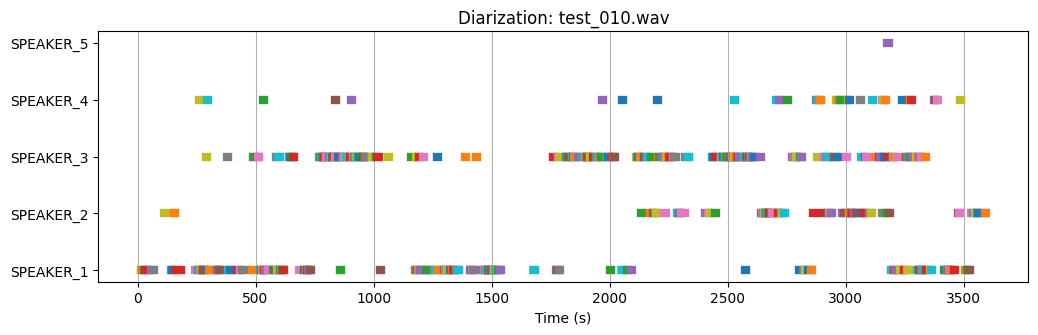

In [19]:
def plot_diarization_turns(turns, title="Diarization timeline"):
    if not turns:
        print("No turns to plot.")
        return
    speakers = sorted({t["speaker_id"] for t in turns})
    spk_to_y = {s: i for i, s in enumerate(speakers)}

    plt.figure(figsize=(12, 1 + 0.45 * len(speakers)))
    for t in turns:
        y = spk_to_y[t["speaker_id"]]
        plt.plot([t["start_time"], t["end_time"]], [y, y], linewidth=6)
    plt.yticks(range(len(speakers)), speakers)
    plt.xlabel("Time (s)")
    plt.title(title)
    plt.grid(True, axis="x")
    plt.show()

if wav_paths:
    diar = diarize_file(wav_paths[0])
    plot_diarization_turns(diar, title=f"Diarization: {wav_paths[0].name}")


## 15) Batch diarization + CSV export
Runs `diarize_file()` over all audio files with a progress bar, serializes each diarization result as JSON per `filename`, and writes a submission-ready CSV to `OUT_PATH` (then previews the first rows).


In [20]:
pred_rows = []
for stem, wav_path in tqdm(list(zip(stems, wav_paths)), total=len(wav_paths), desc="Diarizing"):
    diar = diarize_file(wav_path)
    pred_rows.append({
        "filename": stem,
        "diarization": json.dumps(diar, ensure_ascii=False),
    })

sub_df = pd.DataFrame(pred_rows)
sub_df.to_csv(OUT_PATH, index=False)

OUT_PATH, sub_df.head()

Diarizing:   0%|          | 0/14 [00:00<?, ?it/s]

(PosixPath('submission.csv'),
    filename                                        diarization
 0  test_010  [{"start_time": 13.14, "end_time": 15.66, "spe...
 1  test_012  [{"start_time": 0.66, "end_time": 9.1, "speake...
 2  test_016  [{"start_time": 35.57, "end_time": 37.1, "spea...
 3  test_018  [{"start_time": 0.6, "end_time": 5.13, "speake...
 4  test_019  [{"start_time": 2.07, "end_time": 6.6, "speake...)